In [47]:
# importing libraries
import pandas as pd  # lib to handle data
from sklearn.model_selection import train_test_split # lib to separate / train data
from sklearn.preprocessing import StandardScaler # help to scale the data (k-nn)
from sklearn.neighbors import KNeighborsClassifier # k-nn algorithm
from sklearn.datasets import make_classification # k-nn algorithm

# importa as bibliotecas de análise da performance do modelo
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
# importa a biblioteca que auxilia a plotar os dados visualmente
import matplotlib.pyplot as plt


In [48]:
# generate the data simulation (simulate data from machine)
X, y = make_classification(n_samples=1000, n_features=4, n_informative=3,
                           n_redundant=1, random_state=42, weights=[0.9, 0.1])
print(X)


[[-1.63471591  0.12003979 -0.95586965 -0.64832819]
 [ 0.44527728 -1.98619811  0.21974397  1.86935094]
 [-1.89222477 -1.03217141  1.54176061 -0.1757323 ]
 ...
 [-0.36820117 -1.60251526 -0.45685167  1.30021259]
 [ 0.47022793 -2.73756477 -0.47538663  2.64303567]
 [-1.1973278  -1.00274426  1.22921028  0.14879838]]


In [49]:
print(y)

[0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 1 0 0 1 0 0 0 0 1 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 1 0 1
 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 1 0 0 0 0 1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0
 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 1
 1 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0
 0 1 0 0 0 0 0 0 0 1 0 0 

In [50]:
# create data frame (like a table) using the data from machine
df_machine = pd.DataFrame(X, columns=['Temp_Rolamento_C', 'Vibracao_Axial',
                                      'Ruido','Corrente_Motor'])
print(df_machine)

     Temp_Rolamento_C  Vibracao_Axial     Ruido  Corrente_Motor
0           -1.634716        0.120040 -0.955870       -0.648328
1            0.445277       -1.986198  0.219744        1.869351
2           -1.892225       -1.032171  1.541761       -0.175732
3            0.081571       -2.216266 -0.718966        2.066282
4           -1.298140       -0.547365 -0.174167       -0.056450
..                ...             ...       ...             ...
995         -1.062780       -1.599082 -1.973174        1.248611
996         -0.982087       -0.767210  0.357611        0.181480
997         -0.368201       -1.602515 -0.456852        1.300213
998          0.470228       -2.737565 -0.475387        2.643036
999         -1.197328       -1.002744  1.229210        0.148798

[1000 rows x 4 columns]


In [51]:
# add the 'y' data in the table (if the machine is broken or not)
df_machine['Falha'] = y
print(df_machine)

     Temp_Rolamento_C  Vibracao_Axial     Ruido  Corrente_Motor  Falha
0           -1.634716        0.120040 -0.955870       -0.648328      0
1            0.445277       -1.986198  0.219744        1.869351      0
2           -1.892225       -1.032171  1.541761       -0.175732      0
3            0.081571       -2.216266 -0.718966        2.066282      0
4           -1.298140       -0.547365 -0.174167       -0.056450      0
..                ...             ...       ...             ...    ...
995         -1.062780       -1.599082 -1.973174        1.248611      0
996         -0.982087       -0.767210  0.357611        0.181480      0
997         -0.368201       -1.602515 -0.456852        1.300213      0
998          0.470228       -2.737565 -0.475387        2.643036      0
999         -1.197328       -1.002744  1.229210        0.148798      0

[1000 rows x 5 columns]


In [52]:
# separate the machine data input in a dataframe
X_df = df_machine[['Temp_Rolamento_C', 'Vibracao_Axial',
                   'Ruido','Corrente_Motor']]
# separate the machine data result in a dataframe
Y_df = df_machine['Falha']

In [53]:
#separa os dados de treinamento e teste (25% para teste e 75% para treinamento)
X_train, X_test, y_train, y_test = train_test_split(X_df, Y_df, test_size=0.25, random_state=42)

In [54]:
scaler = StandardScaler() # lib para colocar as variáveis na mesma escala (k-NN é sensível em escalas)


In [55]:
X_train_scaled = scaler.fit_transform(X_train) # escala os dados de treinamento
X_test_scaled = scaler.transform(X_test) # escala os dados de teste

In [56]:
print(X_train_scaled)

[[ 0.45748597 -0.63372131  0.09173659  0.73187823]
 [-0.53118688 -0.73169991  1.7444023  -0.09212836]
 [ 2.36456272  3.52579218  0.24968207 -1.85776526]
 ...
 [-0.10785969 -0.3273966   0.9544204  -0.02187953]
 [ 0.74983462 -0.95342188  0.15292011  1.12748614]
 [-0.84423691  0.53753304 -1.06916874 -0.59183835]]


In [57]:
knn = KNeighborsClassifier(n_neighbors=5) # instancia o algoritmo observando os 5 vizinhos

In [58]:
knn.fit(X_train_scaled, y_train) # treina o algoritmo com os dados de treinamento

KNeighborsClassifier()

In [59]:
plc_input = pd.DataFrame({
    'Temp_Rolamento_C': [24.3],
    'Vibracao_Axial': [2],
    'Ruido': [40],
    'Corrente_Motor': [35]
})
print("Dados de entrada do PLC:")
print(plc_input)

Dados de entrada do PLC:
   Temp_Rolamento_C  Vibracao_Axial  Ruido  Corrente_Motor
0              24.3               2     40              35


In [60]:
plc_input_scaled = scaler.transform(plc_input)
prediction = knn.predict(plc_input_scaled)

In [61]:
if prediction[0] == 0:
  print("Máquina OK!")
else:
  print("Máquina prestes a falhar!")
  print(plc_input)

Máquina OK!


In [62]:
y_pred = knn.predict(X_test_scaled) # faz a predição com os dados de teste

rate = accuracy_score(y_test,y_pred) # calcula a taxa de acertividade comparando a predição com o real

print(f"Taxa de acertividade: {rate * 100:.2f}%")

Taxa de acertividade: 96.00%


In [63]:
report = classification_report(y_test, y_pred, target_names=['OK', 'Falha'])

print("Relatório de Classificação:")
print(report)


Relatório de Classificação:
              precision    recall  f1-score   support

          OK       0.96      1.00      0.98       224
       Falha       1.00      0.62      0.76        26

    accuracy                           0.96       250
   macro avg       0.98      0.81      0.87       250
weighted avg       0.96      0.96      0.96       250



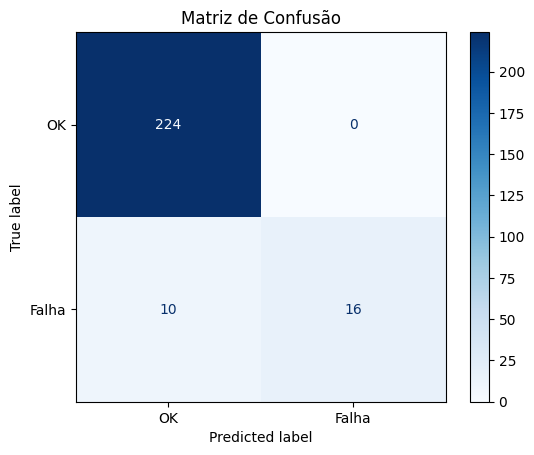

In [64]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['OK', 'Falha'], cmap='Blues')
plt.title("Matriz de Confusão")
plt.show()